# 06b: Test-Set (Holdout) Sensitivity, Band-Only Baseline

B Steele, Colorado State University, ROSSyndicate — last updated Oct 8, 2026

**Pipeline step 06b · Python · run from `regional_clarity/`**

- **Purpose:** Repeat the 16-draw holdout sweep of `06_test_set_sensitivity.ipynb` with the band-only architectures, and compare each draw with production's.
- **Inputs:** `aquamatch_files/base_with_splits.parquet`; `xg_models/v3_band_only/seed*/` (`final_eval_summary.json`, `holdout_predictions.parquet`, `holdout_predictions_full.parquet`); `xg_models/test_set_sensitivity/holdout_sweep_results.parquet` (for comparison).
- **Outputs:** `xg_models/test_set_sensitivity_band_only/`: `holdout_sweep_results.parquet`, `sweep_summary.json`, `holdout_sensitivity.png`.
- **Previous:** [05b · Evaluate ensemble (band-only)](05b_evaluate_ensemble_band_only.ipynb)
- **Next:** [07b · Regional application (band-only)](07b_regional_application_band_only.Rmd)

`06_test_set_sensitivity.ipynb` showed that production's holdout RMSE depends heavily on which HUC8s land in the holdout. This notebook asks the same question of the band-only ensemble, and whether the gap between the two models holds across partitions or is specific to the production holdout.

**Design.** Identical to `06`: each of the 10 band-only seeds' already-selected feature sets and tuned hyperparameters (from `04b_make_models_band_only.ipynb`) is reused unchanged, each seed's model is refit on each draw's full CV pool as in `06`, and only the partition changes. The 15 alternative holdout seeds are the same ones `06` swept, so each draw here pairs with the same draw there. The same caveat applies: this holds architecture fixed and does not re-run feature selection or tuning per draw.

## Setup

Import the shared modeling modules, set the reference holdout seed (12, the production holdout) and the 15 alternative holdout seeds to sweep, and rebuild the modeling table with the same feature engineering used in `04b` and `05b`.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("python").resolve()))
import features
import metrics as M
import model_xgb
import spatial_cv

AQUAMATCH_DIR = Path("aquamatch_files")
SEED_MODELS_DIR = Path("xg_models") / "v3_band_only"
OUT_DIR = Path("xg_models") / "test_set_sensitivity_band_only"
PRODUCTION_SWEEP = Path("xg_models") / "test_set_sensitivity" / "holdout_sweep_results.parquet"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "harmonized_value"
SEEDS = list(range(601, 611))  # the 10 already-selected band-only architectures from 04b_make_models_band_only.ipynb
REFERENCE_HOLDOUT_SEED = spatial_cv.HOLDOUT_SEED  # 12, the production holdout used everywhere else
SWEEP_HOLDOUT_SEEDS = [s for s in range(1, 17) if s != REFERENCE_HOLDOUT_SEED]  # 15 fresh draws

ROSS_LT_PAL = ["#002EA3", "#E70870", "#256BF5", "#745CFB", "#1E4D2B", "#56104E"]

df = pd.read_parquet(AQUAMATCH_DIR / "base_with_splits.parquet")
df = features.add_spectral_indices(df)
df = features.coarsen_site_features(df)
print(f"{len(df):,} rows, {df.shape[1]} columns")

11,143 rows, 62 columns


## Load each seed's already-selected architecture

Each of `601`-`610` already went through independent correlation pruning, backward elimination, and gap-aware tuning against the seed-12 holdout in `04b_make_models_band_only.ipynb`. `final_eval_summary.json` has both the resulting feature set and tuned hyperparameters saved per seed — reused unchanged for every holdout draw below.

In [2]:
seed_configs = {}
for seed in SEEDS:
    summary = json.load(open(SEED_MODELS_DIR / f"seed{seed}" / "final_eval_summary.json"))["xgboost"]
    seed_configs[seed] = dict(features=summary["features"], params=summary["params"])

n_feats = [len(c["features"]) for c in seed_configs.values()]
print(f"feature-set sizes across the 10 seeds: min={min(n_feats)}, max={max(n_feats)}, "
      f"{len(set(tuple(sorted(c['features'])) for c in seed_configs.values()))} distinct feature sets")

feature-set sizes across the 10 seeds: min=12, max=13, 3 distinct feature sets


## Sweep holdout definitions

For each candidate `holdout_seed`, `spatial_cv.build_splits` redraws which HUC8 groups fall into the holdout vs. the CV pool from scratch (the same bin-packing logic used everywhere else, just reseeded). For each of the 10 seed-configs, `build_folds` gives that draw's 4-fold arrangement of the new CV pool. The seed's saved features and hyperparameters are run through that 4-fold CV to set the number of boosting rounds (the mean of the folds' early-stopped round counts); the seed's model is then fit once on the draw's whole CV pool and evaluated on the new holdout. Averaging the 10 seeds' predictions gives one ensemble RMSE per holdout draw — the same procedure `04b_make_models_band_only.ipynb` used for `holdout_seed=12`, just repeated with a different partition each time. The `holdout_seed=12` row reuses `04b_make_models_band_only.ipynb`'s already-saved predictions (`holdout_predictions_full.parquet`) rather than retraining. The four fold models' averaged predictions are also scored in every draw, for the 40-member reference at the end.

Also tracked per draw: how much of each structurally-hard basin (HUC4 1701's forested lake cluster, HUC4 1407 / Lake Powell) lands in that draw's holdout, as in `06`.

In [3]:
def hard_basin_shares(df_i):
    shares = {}
    for huc4, label in [("1701", "huc1701_share"), ("1407", "huc1407_share")]:
        total = (df_i["HUC4"] == huc4).sum()
        in_holdout = ((df_i["HUC4"] == huc4) & df_i["is_holdout"]).sum()
        shares[label] = float(in_holdout / total) if total else np.nan
    return shares


def run_holdout_draw(holdout_seed, df, seed_configs, retrain=True, cached_metrics=None, cached_fold_metrics=None):
    df_i = spatial_cv.build_splits(df, holdout_seed=holdout_seed, ensemble_seeds=SEEDS)
    test_i = df_i[df_i["is_holdout"]].reset_index(drop=True)

    if retrain:
        # one row per (siteSR_id, date, seed) prediction - concatenated and deduped
        # below the exact same way 04b_make_models_band_only.ipynb's saved holdout predictions are, since a
        # meaningful minority of (siteSR_id, date) groups have multiple rows (e.g.
        # multi-mission matches on the same date) and every other evaluation in this
        # project scores one prediction per (siteSR_id, date), not per raw row
        seed_pred_rows = []
        cv_pool_i = df_i[~df_i["is_holdout"]].reset_index(drop=True)
        for seed, cfg in seed_configs.items():
            feats, params = cfg["features"], cfg["params"]
            # this draw's 4-fold CV sets the round count (mean of the folds' early-stopped
            # rounds); the seed's model is then fit once on the draw's whole CV pool
            folds = spatial_cv.build_folds(df_i, seed)
            fold_models = model_xgb.train_fold_models(folds, feats, TARGET, params)
            model = model_xgb.train_full_model(cv_pool_i, feats, TARGET, params,
                                               model_xgb.cv_num_rounds(fold_models))
            pred = model_xgb.predict_ensemble([model], test_i[feats])
            # the four fold models' own average, kept for the 40-member reference below
            pred_fold = model_xgb.predict_ensemble(fold_models, test_i[feats])
            seed_pred_rows.append(pd.DataFrame({
                "siteSR_id": test_i["siteSR_id"].values, "date": test_i["date"].values,
                "y": test_i[TARGET].values, "pred": pred, "pred_fold": pred_fold}))
        all_seed_preds = pd.concat(seed_pred_rows, ignore_index=True)
        deduped = all_seed_preds.groupby(["siteSR_id", "date"]).agg(
            y=("y", "first"), pred=("pred", "mean"), pred_fold=("pred_fold", "mean")).reset_index()
        result = M.all_metrics(deduped["y"], deduped["pred"])
        fold_result = M.all_metrics(deduped["y"], deduped["pred_fold"])
    else:
        result = dict(cached_metrics)
        fold_result = dict(cached_fold_metrics)

    result.update({f"{k}_fold40": v for k, v in fold_result.items() if k != "n"})
    result["holdout_seed"] = holdout_seed
    result["n_holdout"] = len(test_i)
    result.update(hard_basin_shares(df_i))
    return result


def load_reference(fname):
    rows = [pd.read_parquet(SEED_MODELS_DIR / f"seed{s}" / fname) for s in SEEDS]
    ens = pd.concat(rows, ignore_index=True).groupby(["siteSR_id", "date"]).agg(
        y=("y", "first"), pred=("pred", "mean")).reset_index()
    return M.all_metrics(ens["y"], ens["pred"])


# reference: 04b_make_models_band_only.ipynb's already-trained-and-saved holdout_seed=12 ensemble, no retraining
reference_metrics = load_reference("holdout_predictions_full.parquet")
reference_metrics_fold40 = load_reference("holdout_predictions.parquet")
print(f"reference (holdout_seed={REFERENCE_HOLDOUT_SEED}): {reference_metrics}")

results = [run_holdout_draw(REFERENCE_HOLDOUT_SEED, df, seed_configs, retrain=False,
                             cached_metrics=reference_metrics, cached_fold_metrics=reference_metrics_fold40)]

t_start = time.time()
for i, hs in enumerate(SWEEP_HOLDOUT_SEEDS):
    t0 = time.time()
    results.append(run_holdout_draw(hs, df, seed_configs))
    print(f"[{i+1}/{len(SWEEP_HOLDOUT_SEEDS)}] holdout_seed={hs}: "
          f"rmse={results[-1]['rmse']:.4f} n={results[-1]['n_holdout']} "
          f"({time.time()-t0:.0f}s, total {time.time()-t_start:.0f}s)", flush=True)

results_df = pd.DataFrame(results).sort_values("holdout_seed").reset_index(drop=True)
results_df.to_parquet(OUT_DIR / "holdout_sweep_results.parquet")
results_df[[c for c in results_df.columns if not c.endswith("_fold40")]]

reference (holdout_seed=12): {'rmse': 1.3804904187528886, 'mae': 1.0218711782644356, 'mape': 0.43056247245601564, 'bias': 0.09902969514244872, 'p_bias': 3.0702078056290394, 'smape': 0.34288944237668045, 'r2': 0.5587528516715039, 'n': 1833}


[1/15] holdout_seed=1: rmse=1.5166 n=2364 (32s, total 32s)


[2/15] holdout_seed=2: rmse=1.5892 n=2281 (31s, total 63s)


[3/15] holdout_seed=3: rmse=1.8710 n=2334 (23s, total 85s)


[4/15] holdout_seed=4: rmse=1.2601 n=2137 (33s, total 118s)


...

[12/15] holdout_seed=13: rmse=2.1766 n=2172 (37s, total 352s)


[13/15] holdout_seed=14: rmse=1.1280 n=2552 (27s, total 379s)


[14/15] holdout_seed=15: rmse=1.7370 n=2259 (30s, total 409s)


[15/15] holdout_seed=16: rmse=1.5182 n=2350 (29s, total 438s)


,rmse,mae,mape,bias,p_bias,smape,r2,n,holdout_seed,n_holdout,huc1701_share,huc1407_share
0,1.516624,1.116761,0.429609,0.259324,7.450842,0.331770,0.532630,1883,1,2364,0.000000,0.000000
1,1.589213,1.124333,0.384550,0.033115,0.857966,0.309741,0.534089,1745,2,2281,0.114592,0.000000
2,1.871032,1.289675,0.559261,0.126075,3.147317,0.354132,0.497352,2133,3,2334,0.691674,0.482935
3,1.260128,0.901608,0.353471,0.011811,0.355220,0.291496,0.540563,1594,4,2137,0.012366,0.000000
4,1.891809,1.317584,0.345545,-0.578524,-13.641770,0.339960,0.505553,1721,5,2274,0.338005,0.237201
5,1.932651,1.309791,0.562389,0.086685,2.347371,0.369410,0.482445,1792,6,2246,0.256389,0.482935
6,1.585696,1.134865,0.440127,-0.047296,-1.152656,0.320252,0.601947,1970,7,2099,0.469085,0.232082
7,1.038480,0.714268,0.806251,0.099930,4.378636,0.450356,0.758679,1667,8,2009,0.019786,0.232082
8,1.603250,1.103458,0.596741,-0.115503,-3.465533,0.378781,0.616707,1910,9,2186,0.029678,0.232082
9,1.395211,0.990718,0.533173,0.049361,1.596030,0.368701,0.601500,1647,10,2219,0.142622,0.000000


## Distribution of holdout RMSE across partition draws

Summarize ensemble RMSE across all 16 holdout draws, and report where the fixed holdout (seed 12) falls in that distribution (the share of draws with a lower RMSE). The summary is saved to `sweep_summary.json`, with the 40-member fold ensemble's distribution alongside for reference.

In [4]:
summary_stats = results_df["rmse"].describe()
reference_rank = (results_df["rmse"] < reference_metrics["rmse"]).mean()
print(summary_stats)
print(f"\nreference draw (holdout_seed={REFERENCE_HOLDOUT_SEED}) rmse={reference_metrics['rmse']:.4f} m, "
      f"{reference_rank:.0%} of the {len(results_df)} draws score better (lower RMSE)")

with open(OUT_DIR / "sweep_summary.json", "w") as fh:
    json.dump(dict(reference_holdout_seed=REFERENCE_HOLDOUT_SEED, reference_metrics=reference_metrics,
                   n_draws=len(results_df), rmse_stats=summary_stats.to_dict(),
                   reference_rmse_percentile=float(reference_rank),
                   reference_metrics_fold40=reference_metrics_fold40,
                   rmse_fold40_stats=results_df["rmse_fold40"].describe().to_dict()), fh, indent=2, default=str)

count    16.000000
mean      1.586921
std       0.305844
min       1.038480
25%       1.391531
50%       1.587455
75%       1.792420
max       2.176641
Name: rmse, dtype: float64

reference draw (holdout_seed=12) rmse=1.3805 m, 19% of the 16 draws score better (lower RMSE)


Left: the distribution of holdout RMSE across draws, with the fixed holdout (seed 12) marked. Right: each draw's RMSE against the share of Lake Powell (HUC4 1407) rows that landed in its holdout. The correlations for both Lake Powell and the HUC 1701 lake cluster are given in the title.

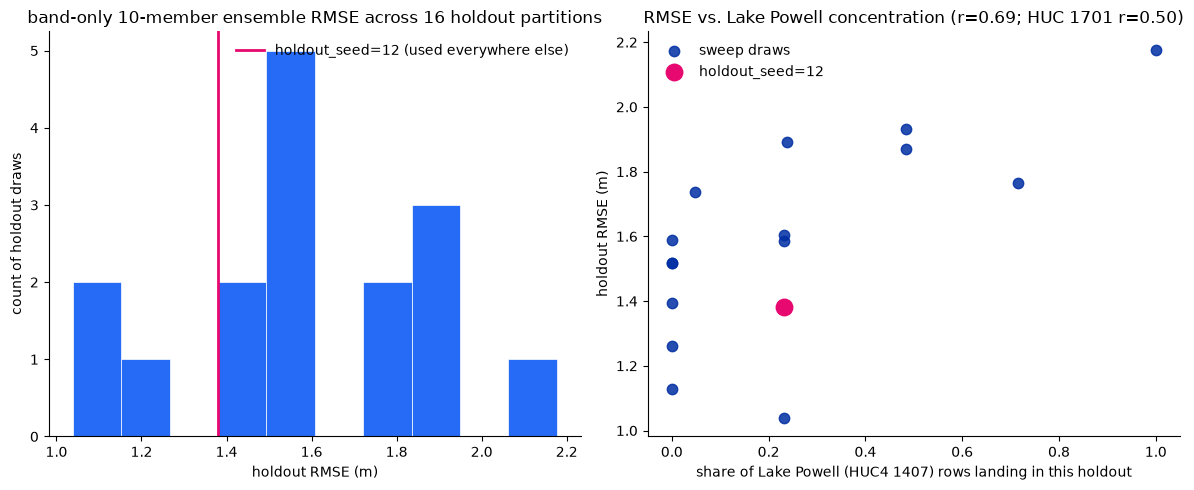

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.hist(results_df["rmse"], bins=10, color=ROSS_LT_PAL[2], edgecolor="white", linewidth=0.5)
ax.axvline(reference_metrics["rmse"], color=ROSS_LT_PAL[1], linewidth=2,
           label=f"holdout_seed={REFERENCE_HOLDOUT_SEED} (used everywhere else)")
ax.set_xlabel("holdout RMSE (m)")
ax.set_ylabel("count of holdout draws")
ax.set_title(f"band-only 10-member ensemble RMSE across {len(results_df)} holdout partitions")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")

# Lake Powell's (HUC4 1407) share of the holdout, as in 06
ax = axes[1]
ax.scatter(results_df["huc1407_share"], results_df["rmse"], color=ROSS_LT_PAL[0], alpha=0.85, s=56,
           label="sweep draws", zorder=3)
ref_row = results_df[results_df["holdout_seed"] == REFERENCE_HOLDOUT_SEED].iloc[0]
ax.scatter([ref_row["huc1407_share"]], [ref_row["rmse"]], color=ROSS_LT_PAL[1], s=141, zorder=5,
           label=f"holdout_seed={REFERENCE_HOLDOUT_SEED}")
r_1407 = results_df["huc1407_share"].corr(results_df["rmse"])
r_1701 = results_df["huc1701_share"].corr(results_df["rmse"])
ax.set_xlabel("share of Lake Powell (HUC4 1407) rows landing in this holdout")
ax.set_ylabel("holdout RMSE (m)")
ax.set_title(f"RMSE vs. Lake Powell concentration (r={r_1407:.2f}; HUC 1701 r={r_1701:.2f})")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.savefig(OUT_DIR / "holdout_sensitivity.png", dpi=150)
plt.show()

## Comparison with production, draw by draw

Each holdout seed defines the same partition in both sweeps, so the per-draw difference isolates the feature pool. Negative ΔRMSE means production is better on that draw.

In [6]:
prod_sweep = pd.read_parquet(PRODUCTION_SWEEP)
paired = results_df.merge(prod_sweep[["holdout_seed", "rmse", "bias", "r2"]], on="holdout_seed",
                          suffixes=("_band", "_prod"), validate="1:1")
paired["delta_rmse"] = paired["rmse_prod"] - paired["rmse_band"]
paired["delta_rmse_pct"] = 100 * paired["delta_rmse"] / paired["rmse_band"]
print(f"production better on {(paired['delta_rmse'] < 0).sum()}/{len(paired)} draws; "
      f"ΔRMSE mean {paired['delta_rmse'].mean():+.3f} m ({paired['delta_rmse_pct'].mean():+.1f}%), "
      f"range {paired['delta_rmse'].min():+.3f} to {paired['delta_rmse'].max():+.3f} m")
print(f"RMSE spread across draws: band-only sd {paired['rmse_band'].std():.3f} m, "
      f"production sd {paired['rmse_prod'].std():.3f} m")
paired[["holdout_seed", "huc1407_share", "huc1701_share", "rmse_band", "rmse_prod", "delta_rmse",
        "bias_band", "bias_prod"]].round(3)

production better on 16/16 draws; ΔRMSE mean -0.128 m (-7.7%), range -0.269 to -0.011 m
RMSE spread across draws: band-only sd 0.306 m, production sd 0.259 m


,holdout_seed,huc1407_share,huc1701_share,rmse_band,rmse_prod,delta_rmse,bias_band,bias_prod
0,1,0.000,0.000,1.517,1.396,-0.121,0.259,0.316
1,2,0.000,0.115,1.589,1.406,-0.184,0.033,0.001
2,3,0.483,0.692,1.871,1.818,-0.053,0.126,0.106
3,4,0.000,0.012,1.260,1.186,-0.074,0.012,-0.029
4,5,0.237,0.338,1.892,1.622,-0.269,-0.579,-0.290
5,6,0.483,0.256,1.933,1.759,-0.174,0.087,0.053
6,7,0.232,0.469,1.586,1.438,-0.148,-0.047,-0.143
7,8,0.232,0.020,1.038,1.012,-0.027,0.100,-0.008
8,9,0.232,0.030,1.603,1.408,-0.195,-0.116,0.029
9,10,0.000,0.143,1.395,1.306,-0.089,0.049,-0.017


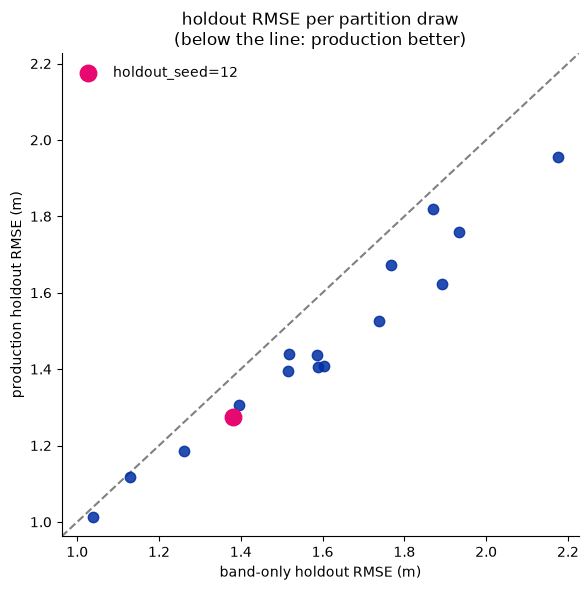

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(paired["rmse_band"], paired["rmse_prod"], color=ROSS_LT_PAL[0], s=56, alpha=0.85, zorder=3)
ref = paired[paired["holdout_seed"] == REFERENCE_HOLDOUT_SEED].iloc[0]
ax.scatter([ref["rmse_band"]], [ref["rmse_prod"]], color=ROSS_LT_PAL[1], s=141, zorder=5,
           label=f"holdout_seed={REFERENCE_HOLDOUT_SEED}")
lims = [min(paired[["rmse_band", "rmse_prod"]].min()) - 0.05, max(paired[["rmse_band", "rmse_prod"]].max()) + 0.05]
ax.plot(lims, lims, ls="--", color="grey")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("band-only holdout RMSE (m)")
ax.set_ylabel("production holdout RMSE (m)")
ax.set_title("holdout RMSE per partition draw\n(below the line: production better)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

## Reference: the 40-member fold ensemble

The same 10 seeds also give a 40-member ensemble: the average of each seed's four fold models, rather than one model refit on the whole CV pool. Its holdout RMSE on the same 16 draws is shown here for reference, as the width of each ensemble's window across partitions. The same partitions, features, and hyperparameters underlie both.

In [8]:
window = pd.DataFrame({
    label: {"min": x.min(), "max": x.max(), "range": x.max() - x.min(), "mean": x.mean(), "sd": x.std(),
            "IQR": x.quantile(0.75) - x.quantile(0.25),
            "seed-12 percentile": (x < x[results_df["holdout_seed"] == REFERENCE_HOLDOUT_SEED].iloc[0]).mean(),
            "r (Lake Powell share)": results_df["huc1407_share"].corr(x),
            "mean |bias|": results_df[bias_col].abs().mean()}
    for label, x, bias_col in [("10-member ensemble", results_df["rmse"], "bias"),
                               ("40-member fold ensemble", results_df["rmse_fold40"], "bias_fold40")]}).T
window.round(3)

,min,max,range,mean,sd,IQR,seed-12 percentile,r (Lake Powell share),mean |bias|
10-member ensemble,1.038,2.177,1.138,1.587,0.306,0.401,0.188,0.687,0.163
40-member fold ensemble,1.051,2.188,1.138,1.583,0.305,0.402,0.188,0.694,0.163


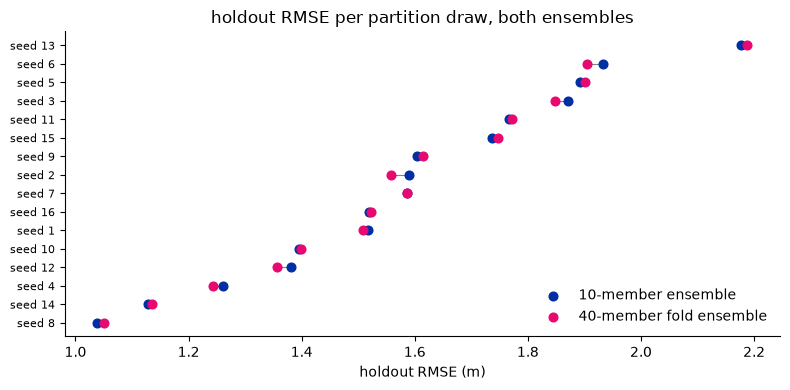

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
order = results_df.sort_values("rmse")
y = np.arange(len(order))
ax.hlines(y, order["rmse"], order["rmse_fold40"], color="grey", linewidth=0.8, zorder=1)
ax.scatter(order["rmse"], y, color=ROSS_LT_PAL[0], s=39, zorder=3, label="10-member ensemble")
ax.scatter(order["rmse_fold40"], y, color=ROSS_LT_PAL[1], s=39, zorder=3, label="40-member fold ensemble")
ax.set_yticks(y)
ax.set_yticklabels([f"seed {s}" for s in order["holdout_seed"]], fontsize=8)
ax.set_xlabel("holdout RMSE (m)")
ax.set_title("holdout RMSE per partition draw, both ensembles")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## Summary

Across the same 16 holdout partitions, the band-only 10-member ensemble's holdout RMSE ranges from 1.04 m to 2.18 m (mean 1.59 m, std 0.31 m — a ~19% coefficient of variation), wider than production's 1.01–1.96 m (std 0.26 m). The fixed holdout (seed 12, RMSE 1.380 m) again sits at the 19th percentile, and Lake Powell's holdout share is again the strongest driver of the spread (r = 0.69; HUC 1701 r = 0.50).

Production outperforms the band-only model on all 16 draws, by 0.128 m (7.7%) on average and by between 0.011 m and 0.269 m on any single draw. The value of the site and weather features is therefore not an artifact of the fixed holdout: it holds on every partition, including the hardest ones. Bias is a different story — mean |bias| across draws is 0.133 m for production and 0.163 m for band-only, with production's the larger on only 6 of the 16 draws, so the fixed holdout's larger production bias does not generalize.

**The 40-member fold ensemble, for reference.** The band-only fold ensemble's window over the same draws is effectively identical to the 10-member ensemble's: 1.05–2.19 m (range 1.14 m for both; std 0.305 m vs. 0.306 m; IQR 0.40 m for both), mean 1.583 m vs. 1.587 m, the same 19th-percentile placement of seed 12, and the same dependence on Lake Powell's share (r = 0.69).